### Diplomatura en Ciencia de Datos 2025 (Trabajo Práctico 2)
# M18: Lectura Distante de Canciones Argentinas
---

- Lautaro Puican Bertone
- Sofía Perón Santana
- Iván Kwist

---

1) Vectorizar el corpus usando el `CountVectorizer` y graficar las palabras más frecuentes en función de la variable target elegida (si es continua, discretizar). Para eso, buscar los parámetros del `CountVectorizer` que arrojen resultados interesantes. En la notebook no es necesario que muestren todos los experimentos, sino únicamente el que más les haya convencido.

2) Repetir el experimento anterior y graficar, pero usando el `TfIdfVectorizer` y haciendo la suma de los scores. ¿Cambian los resultados?

3) Plotear las observaciones en 2 y 3 dimensiones obtenidas con PCA (`TruncatedSVD`), informando en cada caso el porcentaje de varianza explicada. Háganlo para las matrices de 1 y 2, y analicen si en los gráficos la separación de los puntos coincide con su categoría (pueden elegir un subset de observaciones, preferentemente balanceado, para que no tarde tanto en correrles).

4) Aplicar LDA sobre el dataset completo (con o sin lematizar, según elijan) y reportar los resultados. Jueguen con los parámetros para ver si encuentran algún resultado interesante. Y si encuentran, arriesguen alguna interpretación. (Ojo! El análisis de tópicos no habla por sí solo. En todo caso, nos puede llegar a tirar pistas de dónde poner la mirada. Antes de sacar cualquier conclusión es necesario inspeccionar manualmente algunos ejemplos y cruzarlos con otras variables para saber si el modelado descubrió algo interesante o si es un falso positivo).

In [1]:
!python -m spacy download es_core_news_lg # utilizamos el modelo large ya que resultaba en una mejor lematización

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 568.0/568.0 MB 6.9 MB/s eta 0:00:0000:0100:03
✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_lg')


In [2]:
# sklearn
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import TruncatedSVD

# basic
import pandas as pd
import spacy
import missingno as msno
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# others

from tqdm.notebook import tqdm
from collections import Counter
%pip install plotly --quiet
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from imblearn.under_sampling import RandomUnderSampler

Note: you may need to restart the kernel to use updated packages.


In [3]:
#
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords

spanish_stopwords = stopwords.words('spanish')

ModuleNotFoundError: No module named 'nltk'

In [ ]:
# Leer el archivo CSV
df = pd.read_csv("https://drive.google.com/uc?export=download&id=1vSXIKDolSbDvTtohHkhdwgTRGENWSoJ8")
# corpus lo llamamos en el ejercicio 4


In [ ]:
nlp = spacy.load('es_core_news_lg')

def text_2_lemma(text):
    doc = nlp(text)
    return " ".join([token.lemma_ for token in doc])

tqdm.pandas()
df["lyrics_lemma"] = df["lyrics_clean_final"].progress_apply(text_2_lemma)
corpus = df


  0%|          | 0/20736 [00:00<?, ?it/s]

## Respuesta 1 y 2

Unificamos las respuestas de los ejercicios 1 y 2 ya que la idea es comparar sus resultados.



In [ ]:
# vectorizers

min_df = 20
max_df = 0.3
max_features = 1000

count_vectorizer = CountVectorizer(
    stop_words=spanish_stopwords,
    min_df = min_df,
    max_df = max_df,
    max_features=max_features
)

tfidf_vectorizer = TfidfVectorizer(
    stop_words=spanish_stopwords,
    min_df = min_df,
    max_df = max_df,
    max_features=max_features
)

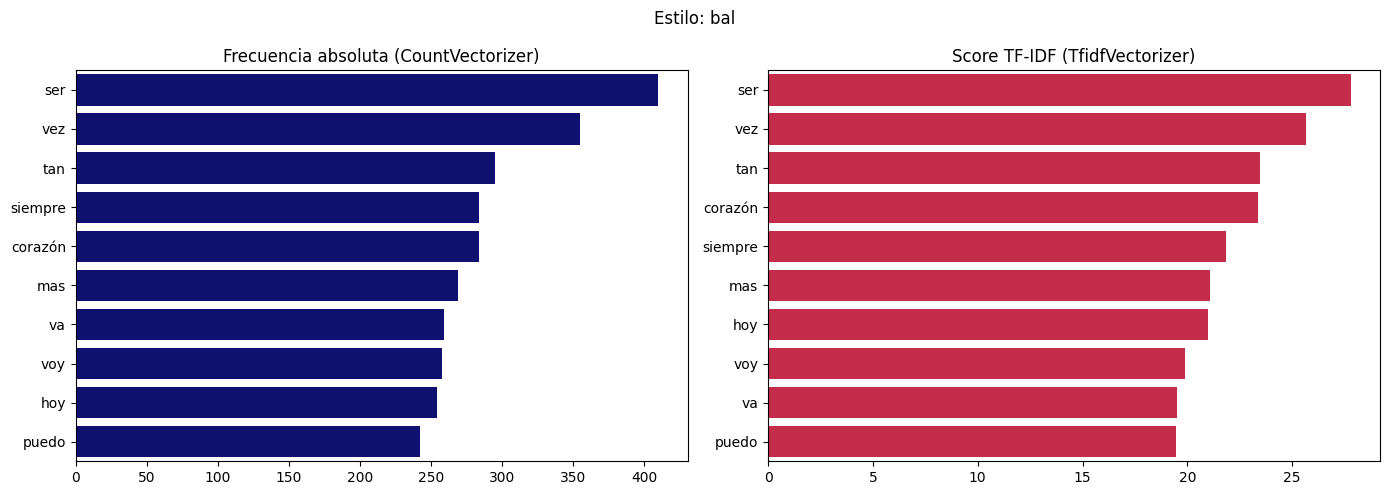

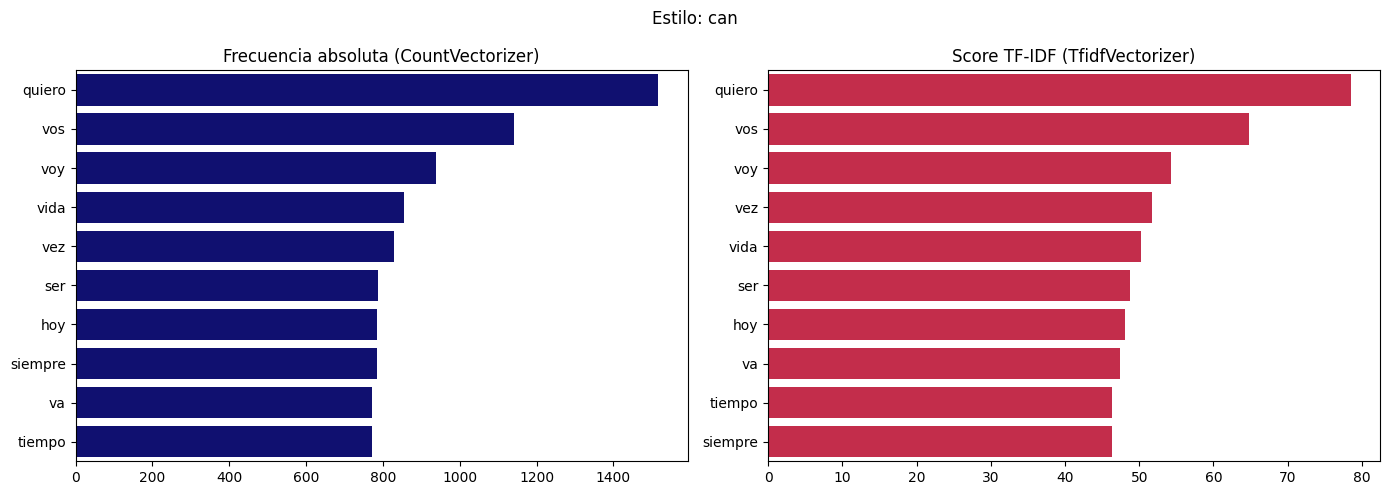

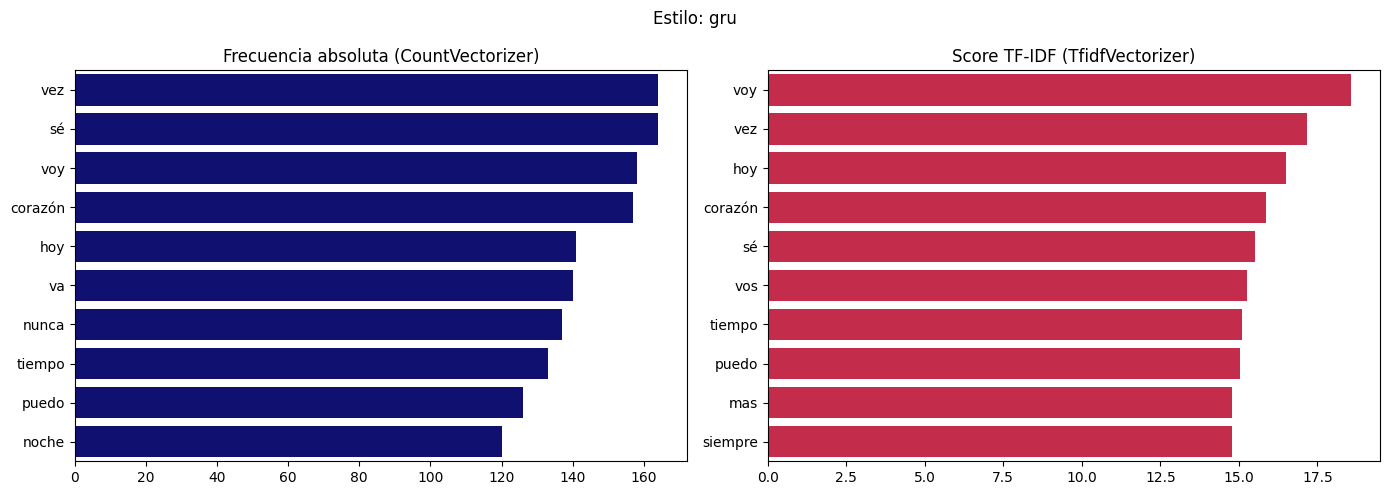

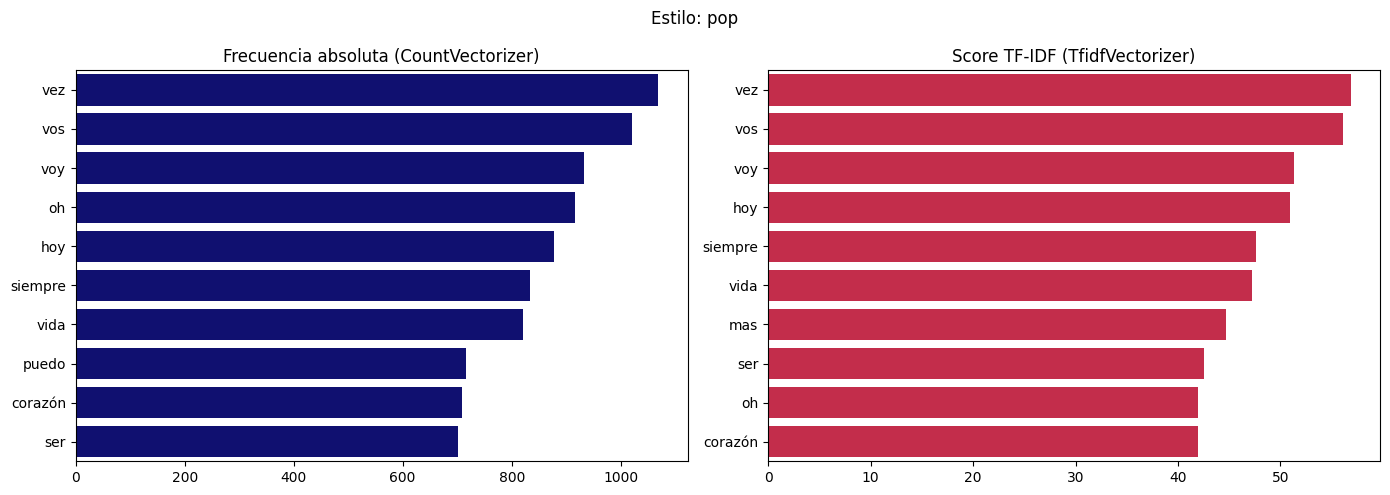

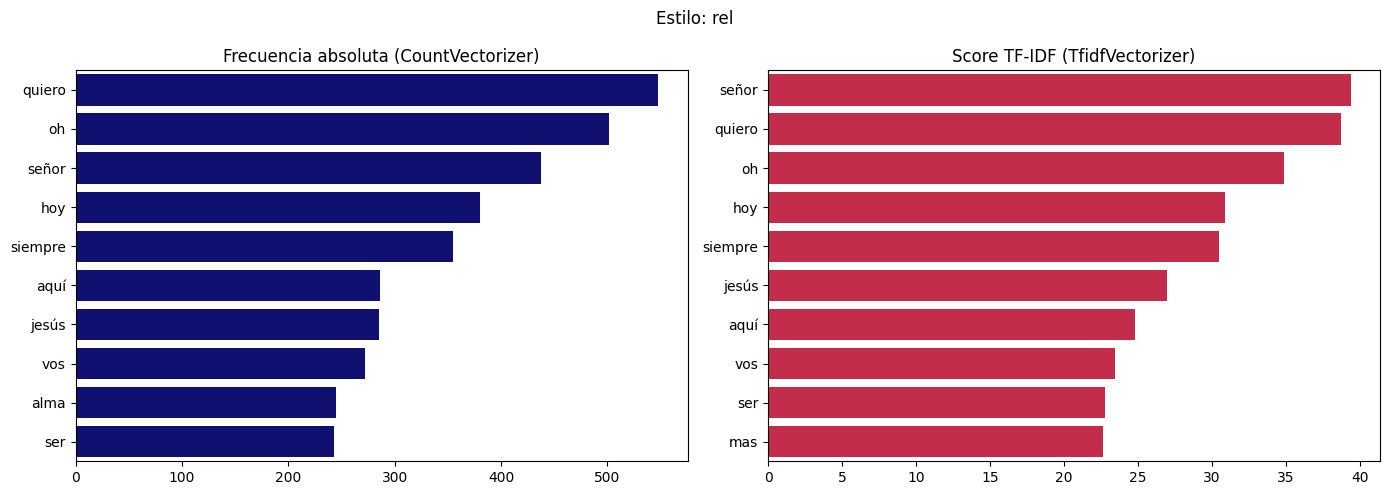

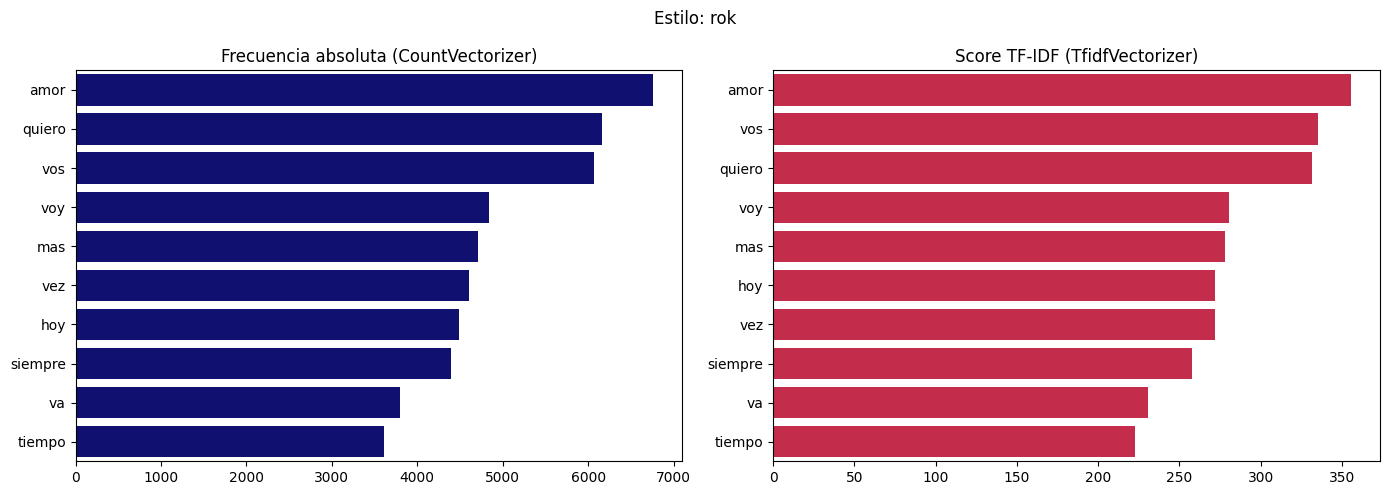

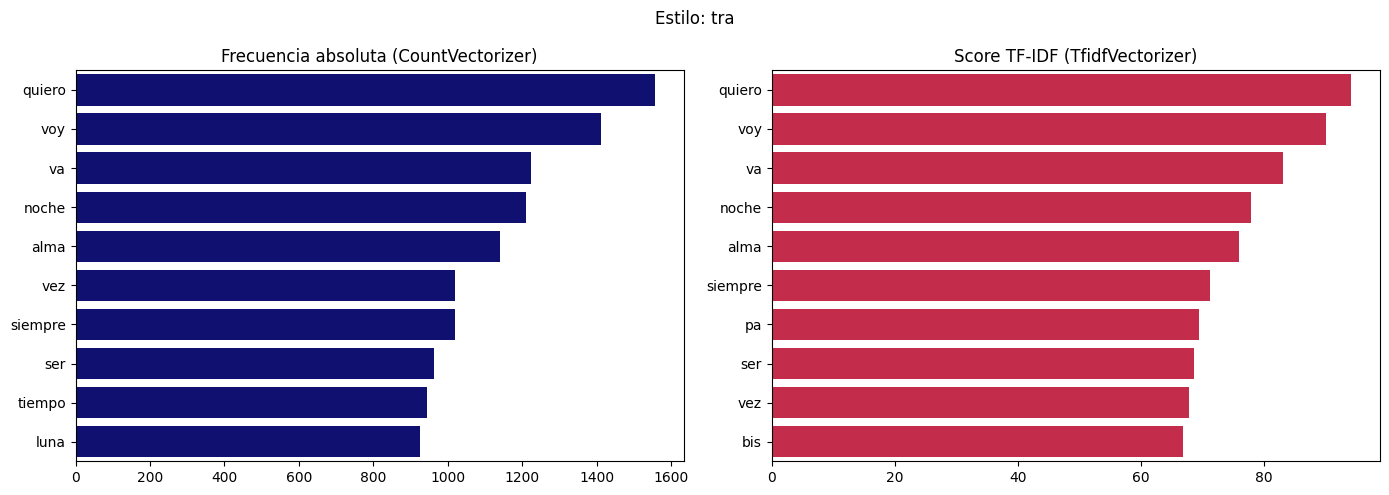

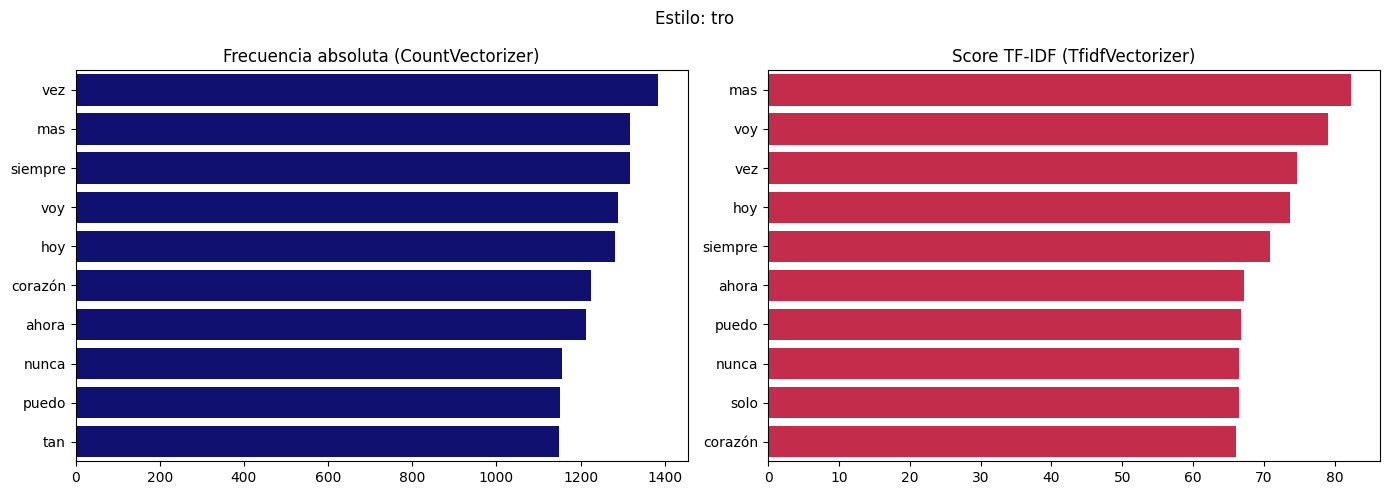

In [ ]:
top_n = 10  # cantidad de palabras a mostrar por gráfico

for estilo in sorted(df['estilo'].unique()):
    grupo = df[df['estilo'] == estilo]

    # CountVectorizer
    X_count = count_vectorizer.fit_transform(grupo['lyrics_clean_final'].fillna(''))
    palabras_count = count_vectorizer.get_feature_names_out()
    suma_count = X_count.sum(axis=0).A1
    top_idx_count = np.argsort(suma_count)[::-1][:top_n]
    top_palabras_count = palabras_count[top_idx_count]
    top_frecuencias_count = suma_count[top_idx_count]

    # TF-IDF
    X_tfidf = tfidf_vectorizer.fit_transform(grupo['lyrics_clean_final'].fillna(''))
    palabras_tfidf = tfidf_vectorizer.get_feature_names_out()
    suma_tfidf = X_tfidf.sum(axis=0).A1
    top_idx_tfidf = np.argsort(suma_tfidf)[::-1][:top_n]
    top_palabras_tfidf = palabras_tfidf[top_idx_tfidf]
    top_frecuencias_tfidf = suma_tfidf[top_idx_tfidf]

    # Graficos lado a lado
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    sns.barplot(x=top_frecuencias_count, y=top_palabras_count, ax=axes[0], color='navy')
    axes[0].set_title('Frecuencia absoluta (CountVectorizer)')

    sns.barplot(x=top_frecuencias_tfidf, y=top_palabras_tfidf, ax=axes[1], color='crimson')
    axes[1].set_title('Score TF-IDF (TfidfVectorizer)')

    plt.suptitle(f'Estilo: {estilo}')
    plt.tight_layout()
    plt.show()

### CountVectorizer vs TfidfVectorizer

Existen cambios entre los resultados de ambos metodos pero no los consideramos significativos. Cambia el orden dentro del top, pero la bolsa de palabras sigue siendo la misma.

Un caso bastante representativo es el genero rok donde las 5 palabras más relevantes coinciden en orden y valor.

El genero que más cambia es el grupero donde el top 10 tiene algunos valores disintos, la diferencia no es solo en el orden

# Respuesta 3

Una vez analizado nuestro corpus con el CountVectorizer y el TfIdfVectorizer, vamos a proceder a decomponer por PCA estas matrices esparsas, graficarlas en 2 y 3 dimensiones y analizar si podemos encontrar una separacion de los estilos en los hiperplanos.

Previo a esto, vamos a crear un subset de datos balanceado. Para ello, utilizaremos un RandomUnderSampler, que tomará N muestras de cada una de las clases de nuestro df, siendo N el valor de la clase con menor representación.

In [ ]:
print('Tamaño de dataset original %s' % Counter(df['estilo']))

Tamaño de dataset original Counter({'rok': 9837, 'tra': 3159, 'tro': 2781, 'can': 1813, 'pop': 1513, 'rel': 724, 'bal': 628, 'gru': 281})


Como podemos observar, el estilo grupero es la clase menos representada, con 281 canciones.

In [ ]:
features_columns = [col for col in df.columns if col != 'estilo']

rus = RandomUnderSampler(random_state=42)

df_rus_features, df_rus_target = rus.fit_resample(
    df[features_columns],
    df['estilo']
)

df_bal = pd.concat([df_rus_features, df_rus_target], axis=1)

print('Tamaño de dataset balanceado %s' % Counter(df_bal['estilo']))

Tamaño de dataset balanceado Counter({'bal': 281, 'can': 281, 'gru': 281, 'pop': 281, 'rel': 281, 'rok': 281, 'tra': 281, 'tro': 281})


Una vez creado nuestro subset de datos comenzaremos a analizar las matrices obtenidas en los ejercicios anteriores.

## 3.1 - Count Vectorizer

Comenzaremos por filtrar nuestra matriz con las filas requeridas:

In [ ]:
X_cv_full = count_vectorizer.fit_transform(df['lyrics_clean_final'].fillna(''))

X_cv_full

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 572430 stored elements and shape (20736, 1000)>

In [ ]:
#df_bal = df_bal.reset_index()
id_bal = df_bal.index
X_cv_bal = X_cv_full[id_bal]

X_cv_bal

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 63786 stored elements and shape (2248, 1000)>

Hecho esto, procedemos a descomponerla con un metodo de reducción de dimencionalidad. En este caso, dado que estamos tratando con matrices esparsas, es más conveniente trabajar con el metodo de Truncated Singular Value Decomposition o TruncatedSVD.

In [ ]:
svd = TruncatedSVD(n_components=50, random_state = 0)

X_cv_reduced = svd.fit_transform(X_cv_bal)
X_cv_reduced.shape

(2248, 50)

In [ ]:
print(svd.explained_variance_ratio_)

[0.02286761 0.02513319 0.02441018 0.01981155 0.01620269 0.01537703
 0.01405843 0.01219534 0.01179156 0.01161024 0.01106117 0.010281
 0.00932072 0.00920249 0.00895637 0.00834919 0.00812083 0.00795851
 0.00751437 0.00727563 0.00706246 0.00686967 0.00673192 0.00663773
 0.0065482  0.00641377 0.00621014 0.00606432 0.00579526 0.00570208
 0.00554018 0.00545127 0.00537092 0.00520407 0.00512306 0.00507241
 0.0049138  0.00476235 0.00463583 0.00459612 0.00449794 0.00443206
 0.00436053 0.004191   0.00406721 0.0040217  0.00400759 0.00389746
 0.00372777 0.00372882]


In [ ]:
np.sum(svd.explained_variance_ratio_)

np.float64(0.4171357441250791)

Como podemos observar, pudimos reducir nuestra dimensionalidad de 1000 a 50 mantener el 43.6 de la varianza de nuestros datos.

Procedemos entonces a graficar nuestros datos en los primeros dos componentes, que representan un 3.06% y 3.15% de los datos respectivamente.

<Axes: >

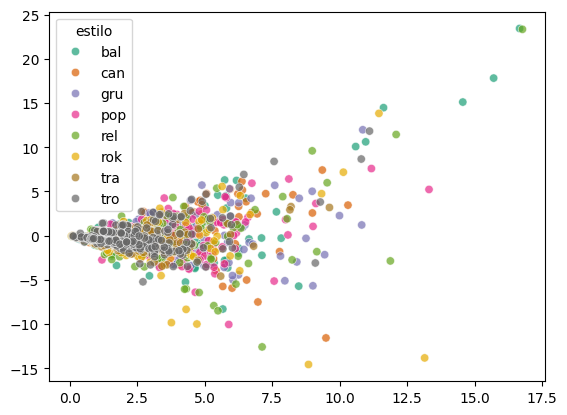

In [ ]:
sns.scatterplot(x = X_cv_reduced[:, 0], y = X_cv_reduced[:, 1], hue = df_bal["estilo"], alpha=0.7, palette=sns.color_palette("Dark2"))

Al graficar los datos con estos componentes no podemos notar distincion alguna en las ubicaciones de los distintos estilos en el hiperplano. Vamos a graficarlos por separado a ver si podemos notar algo interesante:

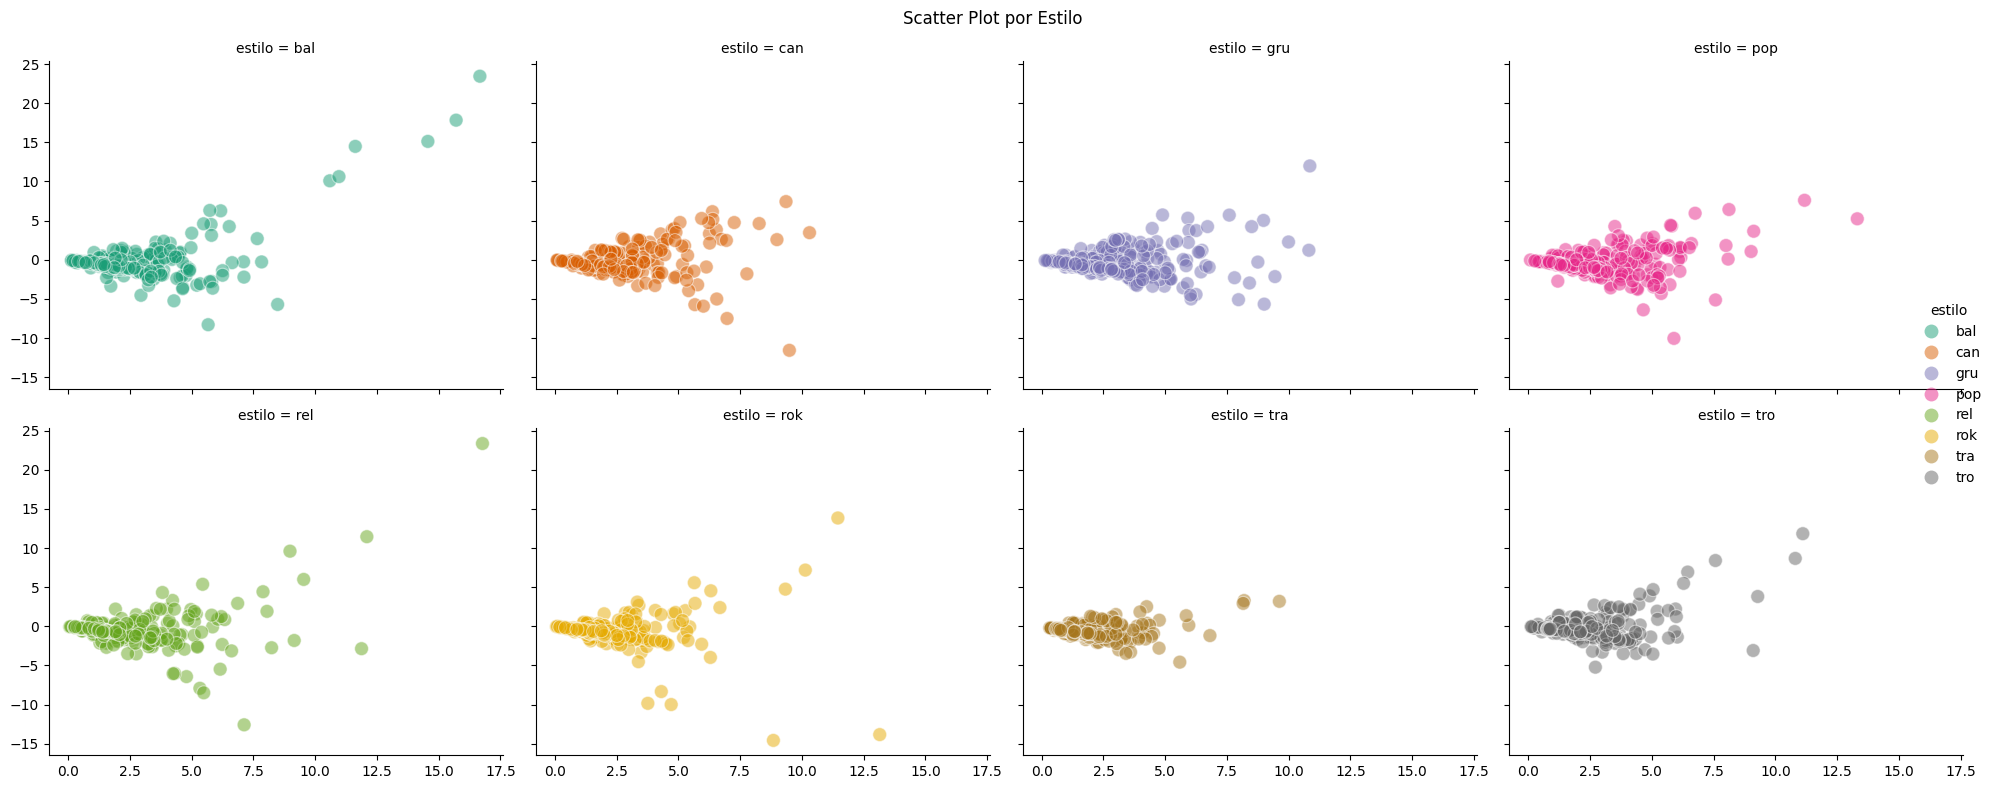

In [ ]:
sns.relplot(x=X_cv_reduced[:, 0], y=X_cv_reduced[:, 1], col=df_bal["estilo"], col_wrap=4, hue=df_bal["estilo"], palette=sns.color_palette("Dark2"), s=100, alpha=0.5, kind='scatter', height=4, aspect=1.2)

plt.suptitle('Scatter Plot por Estilo')
plt.tight_layout()
plt.show()

Como es posible observar, todos los estilos tienen una forma similar en su agrupacion en el plano. De todos modos, si bien no podemos obtener obervaciones interesantes entre generos, podemos quizas analizar la dispercion de estos por separado.

Por ejemplo, podemos decir que las canciones del genero tradicional suelen ser más similares entre sí que aquellas del genero grupero o balada, cuyas muestras se encuentran más separadas.

Vamos a graficarlo en tres dimensiones, agregando el tercer componente, que aporta un 2.37% de la varianza:

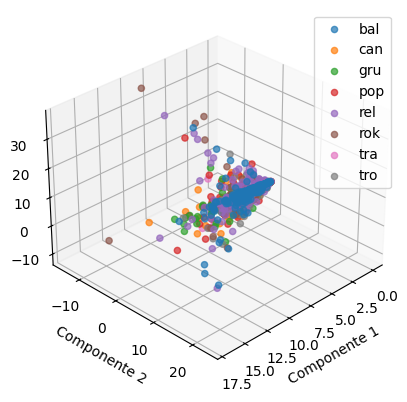

In [ ]:
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

for category in df_bal["estilo"].unique():
    mask = df_bal["estilo"] == category
    ax.scatter(
        X_cv_reduced[mask, 0],
        X_cv_reduced[mask, 1],
        X_cv_reduced[mask, 2],
        label=category,
        alpha=0.7
    )

ax.view_init(elev=30, azim=45)

ax.set_xlabel('Componente 1')
ax.set_ylabel('Componente 2')
ax.set_zlabel('Componente 3')
ax.legend()
plt.show()

Nuevamente, podemos observar que los estilos no parecen tener una ubicacion particular en el hiperplano, sino que todas las canciones parecen estar mezcladas entre si.

Para continuar nuestro analisis, realizaremos el mismo analisis a los resultados obtenidos en el ejercicio 2.

## 3.2 - TF-IDF

Nuevamente, comenzaremos por filtrar nuestra matriz con las filas requeridas y reduciendo su dimensionalidad:

In [ ]:
X_tfidf_full = tfidf_vectorizer.fit_transform(df['lyrics_clean_final'].fillna(''))

X_tfidf_full

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 572430 stored elements and shape (20736, 1000)>

In [ ]:
X_tfidf_bal = X_tfidf_full[id_bal]

X_tfidf_bal

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 63786 stored elements and shape (2248, 1000)>

In [ ]:
X_tfidf_reduced = svd.fit_transform(X_tfidf_bal)
X_tfidf_reduced.shape

(2248, 50)

In [ ]:
print(svd.explained_variance_ratio_)

[0.00413362 0.01086686 0.00948753 0.00847993 0.00682267 0.00666015
 0.00596261 0.0056872  0.00540022 0.00506158 0.00489733 0.00483172
 0.00479488 0.00473582 0.00467103 0.00456941 0.00449087 0.00439862
 0.00429174 0.00420861 0.00415731 0.0041556  0.00404041 0.00395902
 0.00389398 0.00386226 0.00377832 0.00377073 0.00368531 0.00362378
 0.0035497  0.00355792 0.00342411 0.00336084 0.00333307 0.0032892
 0.00326869 0.00323605 0.00319985 0.00317529 0.00313028 0.00310994
 0.00308401 0.00305607 0.00301798 0.00298441 0.00293982 0.00291792
 0.00290539 0.00285981]


In [ ]:
np.sum(svd.explained_variance_ratio_)

np.float64(0.2167794791094747)

En esta ocacion, si bien tambien pudimos reducir nuestra dimensionalidad de 1000 a 50, solamente mantuvimos el 22.1% de la varianza de nuestros datos.

<Axes: >

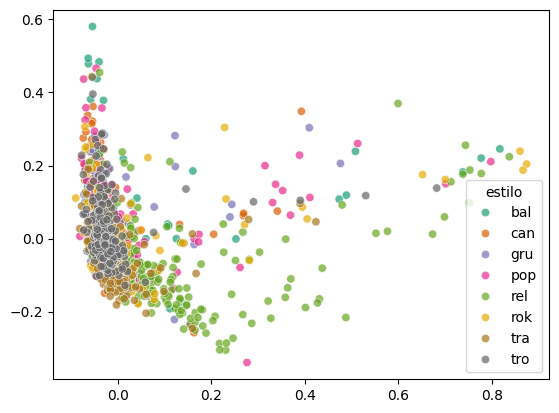

In [ ]:
sns.scatterplot(x = X_tfidf_reduced[:, 1], y = X_tfidf_reduced[:, 2], hue = df_bal["estilo"], alpha=0.7, palette=sns.color_palette("Dark2"))

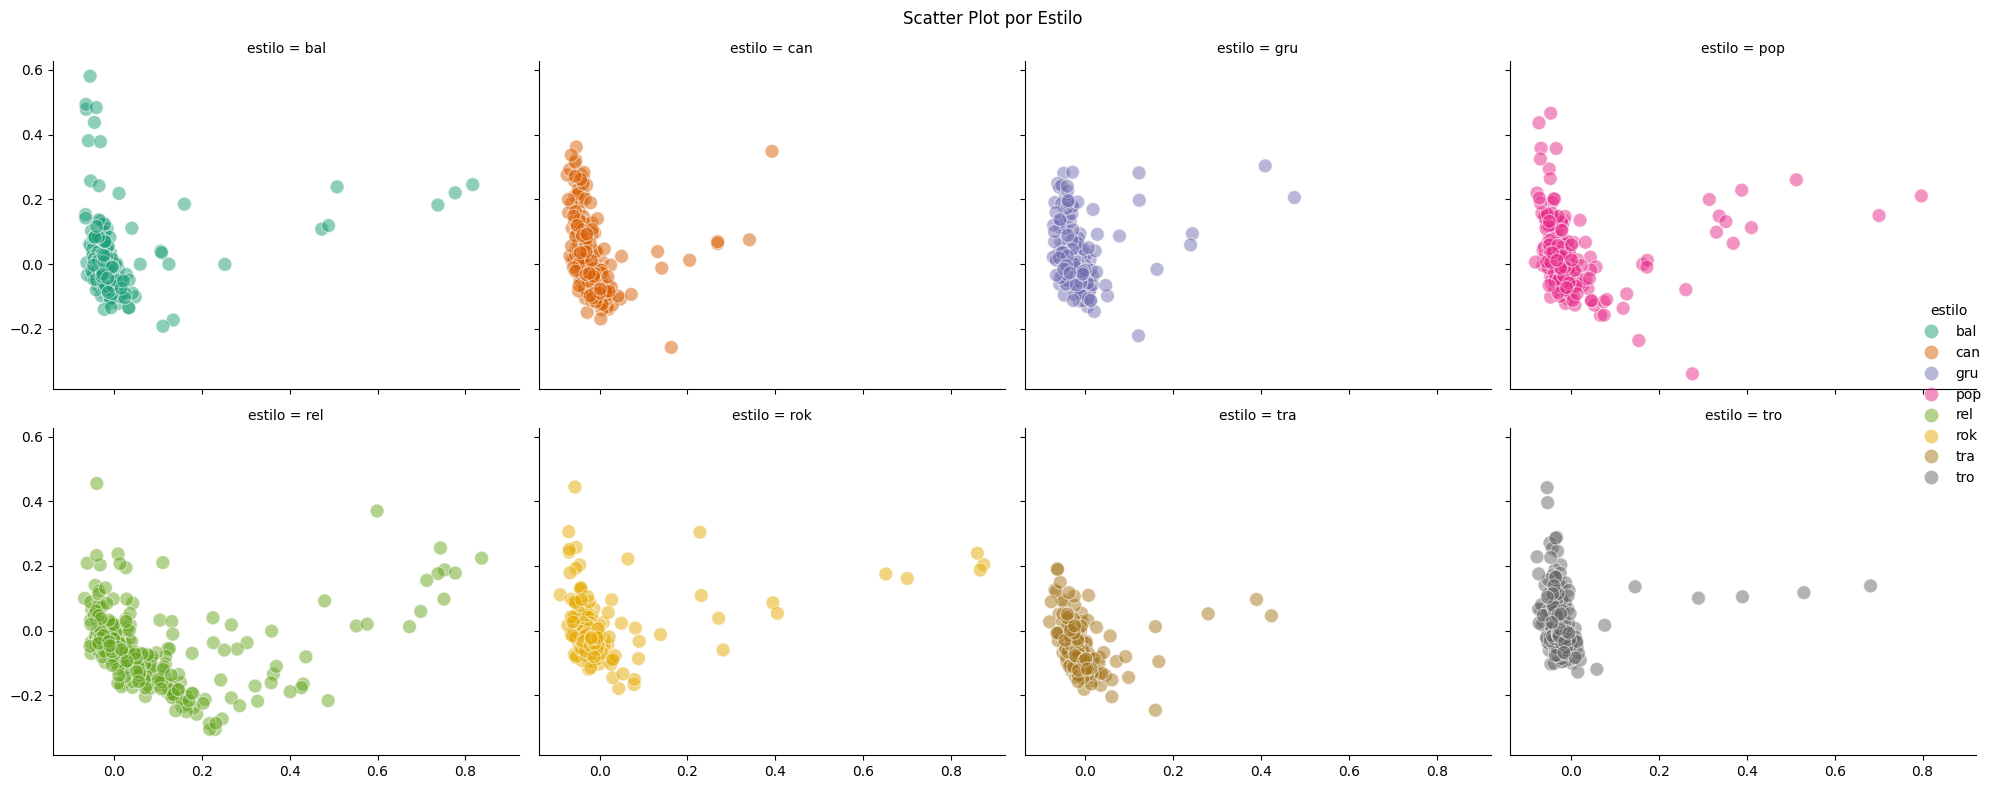

In [ ]:
sns.relplot(x=X_tfidf_reduced[:, 1], y=X_tfidf_reduced[:, 2], col=df_bal["estilo"], col_wrap=4, hue=df_bal["estilo"], palette=sns.color_palette("Dark2"), s=100, alpha=0.5, kind='scatter', height=4, aspect=1.2)

plt.suptitle('Scatter Plot por Estilo')
plt.tight_layout()
plt.show()

Nuevamente, como es posible observar, vemos que todos los estilos tienen una forma similar en su agrupacion en el plano

También podemos volver a observar que el genero tradicional parece estar mas concentrado que generos como el religioso o el pop.

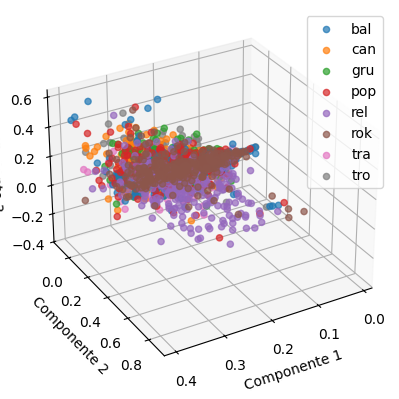

In [ ]:
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

for category in df_bal["estilo"].unique():
    mask = df_bal["estilo"] == category
    ax.scatter(
        X_tfidf_reduced[mask, 0],
        X_tfidf_reduced[mask, 1],
        X_tfidf_reduced[mask, 2],
        label=category,
        alpha=0.7
    )

ax.view_init(elev=30, azim=60)

ax.set_xlabel('Componente 1')
ax.set_ylabel('Componente 2')
ax.set_zlabel('Componente 3')
ax.legend()
plt.show()

Como era de esperar, tampoco podemos observar que los estilos tengan una ubicacion particular en el hiperplano.

## 3.3 - Conclusiones

Tras realizar todos estos gráficos, no notamos método de vectorización o dimensionalidad que permita separar a los estilos en sectores de un hiperplano. Si tenemos en consideración los resultados obtenidos en los Ejercicios 1 y 2, en los cuales las palabras más utilizadas parecian ser las mismas y en virtualmente el mismo orden en todos los estilos, podemos concluir que es esperable que también las canciones esten espacialmente mezcladas al graficarlas en distintos hiperplanos.

## Respuesta 4

### LDA

Para implementar LDA, usaremos la librería `sklearn`. Se aplica `CountVectorizer` y `LatentDirichletAllocation` al corpus completo. Decidimos usar el corpus lematizado porque permite uniformizar y limpiar más las letras.

## LDA

Previo a aplicar LDA, es necesario vectorizar. Decidimos no utilizar el parámetro `stop_words` a diferencia de los ejercicios anteriores ya que en este caso omitirlo permitía obtener resultados más interpretables. Utilizamos este mismo criterio para fijar los hiper-parámetros  ($\alpha , \beta$) del modelo de ajuste. En algunos casos, añadir más componentes disminuía la perplejidad pero las categorías resultantes eran menos interpretables. Priorizamos obtener categorías *más humanas* a un ajuste más preciso pero que no nos daba información.

In [ ]:
corpus = df
vectorizer = CountVectorizer(
    min_df= 20,
    max_df= 0.3,
    max_features= 1000
)
X = vectorizer.fit_transform(corpus["lyrics_lemma"])


In [ ]:
# seteamos los parámetros del modelo LDA
n_components = 6
doc_topic_prior = 0.1 # alpha: cercano a 1 muchos temas en cada documento, cercano a 0, pocos temas con alto p
topic_word_prior = 0.5 # beta: cercano a 1 (p. ej. 0.1), lo mismo: muchas palabras correspondientes a cada tópico; cercano a 0 (p. ej. 0.001), pocas palabras con alto p

In [ ]:
lda = LatentDirichletAllocation(n_components=n_components, doc_topic_prior = doc_topic_prior, topic_word_prior = topic_word_prior, verbose = True, random_state=0, max_iter = 50, evaluate_every = 1)
doc_tema = lda.fit_transform(X)

iteration: 1 of max_iter: 50, perplexity: 542.5167
iteration: 2 of max_iter: 50, perplexity: 526.3718
iteration: 3 of max_iter: 50, perplexity: 513.6940
iteration: 4 of max_iter: 50, perplexity: 504.0102
iteration: 5 of max_iter: 50, perplexity: 497.1896
iteration: 6 of max_iter: 50, perplexity: 492.2542
iteration: 7 of max_iter: 50, perplexity: 488.5660
iteration: 8 of max_iter: 50, perplexity: 485.8557
iteration: 9 of max_iter: 50, perplexity: 483.8179
iteration: 10 of max_iter: 50, perplexity: 482.3658
iteration: 11 of max_iter: 50, perplexity: 481.3540
iteration: 12 of max_iter: 50, perplexity: 480.6056
iteration: 13 of max_iter: 50, perplexity: 480.0208
iteration: 14 of max_iter: 50, perplexity: 479.5738
iteration: 15 of max_iter: 50, perplexity: 479.1994
iteration: 16 of max_iter: 50, perplexity: 478.8979
iteration: 17 of max_iter: 50, perplexity: 478.6312
iteration: 18 of max_iter: 50, perplexity: 478.4281
iteration: 19 of max_iter: 50, perplexity: 478.2278
iteration: 20 of max_

In [ ]:
scaler = MinMaxScaler()

In [ ]:
topico_palabras = scaler.fit_transform(lda.components_.T)
topico_palabras = pd.DataFrame(topico_palabras, index = vectorizer.get_feature_names_out()).round(2)

A continuación, se muestran las palabras más probables en cada tema. Analizaremos uno por uno los tópicos encontrados.

In [ ]:
corpus = df
corpus = pd.concat([corpus, pd.DataFrame(doc_tema, index = corpus.index)], axis = 1)

In [ ]:
for topic_idx, topic in enumerate(lda.components_):
    print(f"Tema #{topic_idx}:")
    print(" ".join([vectorizer.get_feature_names_out()[i] for i in topic.argsort()[:-10 - 1:-1]]))

Tema #0:
vida su amar vivir dios corazón porque dar siempre nuestro
Tema #1:
vos mas nada pero vez mucho decir bien tanto ese
Tema #2:
oh ah uh you nena the and to rock yeah
Tema #3:
su cantar bailar pa venir noche cuando estribillo ese andar
Tema #4:
volver vez más tanto qué decir olvidar pero otro corazón
Tema #5:
luz cielo mar donde ojo mi viento su sueño tiempo


### Tema 0
Las palabras más recurrentes en esta temática son "vida, amar, corazón, vivir, porque, mi, dar, nuestro, dios, morir". Se puede ver que la gran mayoría de las canciones con gran probabilidad de esta temática parecen ser canciones de misa cristiana o similares. Podríamos agrupar esta temática como: **Dios / Religión**.

De todas formas, es curioso como también aparecen letras que hablan de religión pero de géneros muy distintos. Por ejemplo, al observar la letra con más probabilidad de tener este tópico, encontramos que es "Los Idiotas" una canción más rockera y de desesperanza que dice cosas como "Dios no cree en los idiotas".

Otras excepciones son:

- Canciones que hablan de un amigo en particular
  - El Uruguayo, también de Bestia Bebe, habla de un amigo que es un grande
  - Matias es diferente, de Mario Mancini y género folklorica, también dedicada a un gran amigo misericordioso.

    Tiene sentido que el modelo agrupe estas canciones aquí por la similitud con canciones que tratan sobre Jesus.


- El Rey lloró de Pedro Aznar, que cuenta la historia de un rey humilde que rechaza lujos. Es posible que esta abnegación también aparezca en distintas canciones religiosas.

- Amar Amando de Horacio Guarany, que habla de encarar la vida desde el amor.

TOP 10: https://www.youtube.com/watch?v=TjCZ8a84FHM&list=PLRzWM41scuHdJT4pKN_tKf5PcNq7NFkgg

In [ ]:
# Mostrar más caracteres de la columna lyrics_clean_final
pd.set_option('display.max_colwidth', 500)

corpus[['lyrics_clean_final', "artist_name", "estilo", "track_name", 0, 1, 2, 3, 4,5]].sort_values(by = 0, ascending = False).head(10)

,lyrics_clean_final,artist_name,estilo,track_name,0,1,2,3,4,5
4352,estaba solo y buscaba un amigo una mano en soledad y dolor el me rescato dios tiene mucho para sus misericordias nuevas son pues su ayuda viene en oración yo camino solo por fé pues dios tiene el control seguro estoy que dios cuida dios tiene mucho para sus misericordias nuevas son pues su ayuda viene en oración por fé ahora creo llena necesidad yo camino solo por fé tengo un amigo quien lo hablo jesús puedo clamar seguro estoy que dios cuida yo camino solo por fé pues dios tiene el control ...,Claudio Freidzon,rel,Amigos En Lugares Altos,0.994876,0.001025,0.001025,0.001025,0.001025,0.001025
4946,quiero estar dispuesto ser usado por ti quiero oír tu voz guiándome por donde ir yo sé que lo harás yo sé que lo harás porque eres bueno y tu fiel amor perdura para siempre te daré gloria y honra padre eterno ven encuentro tú eres bueno y tu fiel amor perdura para siempre te daré honra y gloria padre eterno ven al encuentro tú eres bueno quiero estar atento cumplir tu voluntad quiero ver tu presencia habitando en este altar yo sé que lo harás yo sé que lo harás porque eres bueno y tu fiel am...,Matthew Hotton,rel,Eres Bueno,0.994418,0.001116,0.001116,0.001116,0.001116,0.001116
4575,llego una reunión amigos una reunión uniformal todos creían ver al mismo pero en su interior no no era igual porqué habia tenido un encuentro con jesús todos esperaban sus bromas su vieja manera actuar todos creían que estaba preocupado que estaba enfermo o se sentía mal pero habia tenido un encuentro con jesús enamorado esta jesús y no puede callar su amor gente le pregunta por qué su vida cambio y él le dice enamorado estoy jesús todos esperaban sus bromas su vieja manera actuar todos creí...,Puerto Seguro,rel,Enamorado,0.993555,0.001289,0.001289,0.001289,0.001289,0.001289
13272,tengo un amigo nuevo él es lo más grande que hay él es colombiano y posee una zurda letal pero no es más grande que ruben paz no es más grande que ruben paz no es más grande que ruben paz no es más grande no es más grande que ruben paz tengo un amigo nuevo él es lo más grande que hay él es colombiano y posee una zurda letal pero no es más grande que ruben paz no es más grande que ruben paz no es más grande que ruben paz no es más grande no es más grande que ruben paz podrán traer nuevas estr...,Bestia Bebe,rok,El Uruguayo,0.993112,0.001378,0.001377,0.001378,0.001378,0.001378
17930,hoy tengo alegría recordar momentos que viven en mente porque encontré un amigo que no es igual todos porque él es diferente él tiene ternura él tiene los ojos buenos él tiene simplemente lo que no tienen todos tiene paz en el alma por eso es diferente qué hermoso sería el mundo como él sería así tan diferente porque él no tiene envidia porque él no tiene odio él no tiene rencor él siempre está presente porque no necesita tener tanto dinero ni lujos desmedidos para vivir un mundo lleno fanta...,Mario Mancini,tra,Matías Es Diferente,0.992710,0.001458,0.001458,0.001458,0.001458,0.001458
4816,no existe un corazón que más que aquel que dijo sí hasta el final no descansó nunca dudó lo hizo todo con y con amor desde el principio recibió gracia que viene solo dios con su pequeñez y su humildad nos muestra el camino santidad uhuhu oohoh uhuhu oohoh madre dios llena gracia reina paz consuelo del alma maría cuídame con tu manto cúbreme sé puente al cielo llévame dios y así como tú quiero llenarme su gracia que se refleje en alma alegría su amor su amor su amor uhuhu oohoh uhuhu oohoh ma...,Veronica Sanfilippo,rel,Llena De Gracia,0.992491,0.001502,0.001502,0.001502,0.001502,0.001502
15566,amar amar amar amar frente amar desde vida hasta muerte amar amar las cosas y gente amar dejar al sin esconderse amar como el niño sus juguetes amar como el pájaro su nido amar amar flor amar el trigo y tu cintura fresca rocío no puedo vivir sin amar amando amar como te y me has amado amar amar sin que sea pecado amar amar amar amando amar es dar vida rato amar es 

### Tema 1

Encontramos las palabras "vos mas nada pero mucho bien decir siempre ese mejor". A priori, no las asociamos a una temática clara. Sin embargo, al observar las letras, podemos ver que prima una temática de tristeza. Particularmente, notamos una tristeza existencialista y relacionada al yo, en contraposición a temáticas más ligadas al desamor. Los ejemplos de probabilidad más alta muestran que se habla de ansiedad "" y soledad. El estilo más representativo es el rock con tendencias punk. Resumimos esta temática como: Tristeza-Existencialismo.

Aparecen canciones con temáticas más ligeras y ritmos más alegres como:

- Cuál de Turf, que habla de desencuentro pero incluye frases como *"hay tanta bellezas sin felicidad"* o  *hay un final donde hubo un comienzo * que encajan en la temática.

- No quiero perderme de Dale Q Va que, si bien tiene un ritmo bailable, tiene fragmentos como *yo sé que veces lo hago mal y aunque lo intento no lo puedo evitar* o  *no me importa lo que diga suerte al fin no vale nada en este mundo*

- Cerca de Daniela Herrera, una canción pop, pero que retrata el desamor también desde una perspectiva existencialista *y afuera esta gente mirando mirando indiferentemente* y, principalmente su estribillo que dice: * quien soy quien fui en donde estoy que nos paso ya no esta por que pensar por que intentar *. Lo mismo sucede con Espera de Valen Etchegoyen, que tiene un ritmo pop liviano pero frases como: *no puedo sòlo quiero desaparecer espera, la locura nos puede matar.*


TOP 10: https://www.youtube.com/watch?v=vr2mbDGPJe0&list=PLRzWM41scuHd0e_d_UsK09ioANaWsxTGd

In [ ]:
# Mostrar más caracteres de la columna lyrics_clean_final
pd.set_option('display.max_colwidth', 500)

corpus[['lyrics_clean_final', "artist_name", "estilo", "track_name", 0, 1, 2, 3, 4,5]].sort_values(by = 1, ascending = False).head(10)

,lyrics_clean_final,artist_name,estilo,track_name,0,1,2,3,4,5
9539,ansiedad ansiedad eso es lo que siento yo el temor morboso fue solo un juego no ansiedad ansiedad es única verdad vez que respiro me sumerjo mas voy cayendo en el pozo profundo del ansia vez que respiro me sumerjo mas mas mas mas ansiedad ansiedad es única verdad ansiedad ansiedad es lo que siento yo ansiedad ansiedad es única verdad vez que respiro me sumerjo mas voy cayendo en el pozo profundo del ansia vez que respiro me sumerjo mas mas mas mas mas ansiedad ansiedad es lo que siento yo do...,Loquero,rok,Ansiedad,0.000778,0.996111,0.000778,0.000778,0.000778,0.000778
6634,todo en base al punteo y desliza púa por esas cuerdas necesito estar un poco más adentro bajo solamente nada va pasar sin reacción todo en base al punteo cuanto tiempo atrás me quedaré mirando todo pasa y yo yo me quedo acá desliza púa por esas cuerdas cuando mas podré resistir cuando mas podré resistir todo en base al punteo y desliza púa por esas cuerdas sé que hay algo mal que ronda en cabeza bajo solamente llega y se va sin reacción todo en base al punteo quiero derrochar o ser feliz con...,Cadena Perpetua,rok,La Reacción,0.000778,0.996111,0.000778,0.000778,0.000778,0.000778
13264,hoy puede ser un dia normal tan corto como los demas en el que tengas que callarte para que puedas escuchar y vos talvez te igual aunque yo siempre busque mas porque paz que el mundo nunca sirvio porque no es paz tan claro como un resplandor mire tus ojos con amor sin importar el egoismo y tu ignorancia veo que hoy venis una vez mas y te abraze sin esperar pronto en el mundo se termina y creiste en una segunda oportunidad estribillo un dia mas para que puedas demostrarme tu cambio al caminar...,Stencil,rok,Un Día Más,0.000975,0.995125,0.000975,0.000976,0.000975,0.000975
12426,¿cuál es manera acercarme vos ¿cuál es manera decírtelo decime cuál cuál cuál ¿cuál es ese sueño que te despertó ¿cuál es el sonido que nos escuchó decime cuál cuál cuál hay tanta bellezas sin felicidad tanto esperarte me puse pensar que hay tantas formas distintas y nunca encontramos cuál hay un final donde hubo un comienzo aunque veces no queramos verlo ni reconocerlo todo es un recuerdo estoy buscando una nueva forma conectar con vos pero no encuentro ¿cuál es manera acercarme vos ¿cuál e...,Turf,rok,Cuál?,0.000994,0.995029,0.000994,0.000994,0.000994,0.000994
20327,tal vez nos alejamos más y ni siquiera lo pudimos notar quizás el miedo avanzar nos separa nos aleja yo sé que veces lo hago mal y aunque lo intento no lo puedo evitar ya sé que no verte es igual pero quiero que lo sepas el amor está esperando en el mismo lugar tal vez no sea el ideal pero quema como quema hoy vine quererte mañana no me importa lo que diga suerte al fin no vale nada en este mundo hoy me toca perderte y sigo porque hoy vine quererte no importa el destino nos golpea más fuerte...,Dale Q Va,tro,No Me Importa Perderme - En Vivo,0.001004,0.994979,0.001004,0.001004,0.001004,0.001004
7994,vos me dijiste que no insista que iva ser mal lo dos yo te miraba y sentia como vos tubieras razón pero en el fondo te mentia que puedo hacer perder yo nunca te voy perder perder yo nunca te voy perder perder yo nunca te voy perder perder no voy darme por vencido no puedo cometer ese error no estubieras confundida yo nunca esperaria vos pero una tarde con amigas te lleve cambiar opinion cambiar opinión perder yo nunca te voy perder perder yo nunca te voy perder perder yo nunca te voy perder ...,Expulsados,rok,Nunca Te Voy a Perder,0.001046,0.994769,0.001046,0.001046,0.001046,0.001046
2967,todo el tiempo en reloj siento que vos sos real no creas que me perdi siempre estuvimos aqui todo cambia y otra ves nos volvemos encontrar creo en todo lo que fui pesar estar aqui y afuera esta gente mirando mirando indiferentemente soy transparente cuando estoy con vos y afuera es otro dia calle esta tan aburrida no tengo prisa cuando estoy con vos cerca vez mas cerca cerca quien soy quien fui en 

### Tema 2

En el tema 2 sucede algo curioso y es que el modelo agrupa letras en inglés. Creemos que lo logra detectando partículas como 'oh ah uh you nena the and to rock yeah'. Aparecen muchas canciones, por ejemplo, de Sumo que son clasificadas como rock nacional pero tienen letras en ingles.

TOP 10: https://www.youtube.com/watch?v=w7DP0BiiHUQ&list=PLRzWM41scuHdUZCshpts7s2DQEh_G4ftH&index=1


In [ ]:
# Mostrar más caracteres de la columna lyrics_clean_final
pd.set_option('display.max_colwidth', 500)

corpus[['lyrics_clean_final', "artist_name", "estilo", "track_name", 0, 1, 2, 3, 4,5]].sort_values(by = 2, ascending = False).head(10)

,lyrics_clean_final,artist_name,estilo,track_name,0,1,2,3,4,5
161,base que después se repite en las estrofas if you want to afraid just afraid if you want to go back home just go back home if you want to comb your hair just comb your hair if you want to alone just alone if you want to watch the sea just watch the sea but it now timing is the answer it now timing is the answer to success if you want to give kiss just give kiss if you want to fall in love just fall in love if you want to never know just never know if you want to throw fit just throw fit if y...,Kevin Johansen,bal,Timing,0.000888,0.000888,0.995559,0.000888,0.000888,0.000888
12161,oh oh oh oh oh oh oh oh oh oh oh oh oh oh oh oh oh oh oh oh oh oh oh oh oh oh oh oh oh oh oh oh oh oh oh oh oh oh oh oh oh oh oh oh moving and fighting and old backstabbing is gonna get you down tonight in babylon town yeah but if you fall on your its not disgrace no one is gonna help you anyhow nowhere oh oh oh oh oh oh oh oh peace and love oh oh oh oh oh oh oh oh peace and love little little people with little little lives in little little homes with little little wives they get up they go...,Sumo,rok,El Reggae de Paz y Amor,0.000956,0.000956,0.995220,0.000956,0.000956,0.000956
12167,sonido telefono punteo del principio o asi sin guitarra hello frank how you doing are you alright durante toda cancion luego se le van agregando sampler teclados y sonidos que hicieron ellos con cualquier cosa sunday morning blues you know just aint the bet when you just want to lie down and have good rest coz the nerves kind of get to you when you feel kinda small and all those things moving up and down against the wall then you tie on that bandana and you feel kind of tough people know you...,Sumo,rok,Hola Frank,0.000956,0.000956,0.995219,0.000956,0.000956,0.000956
11973,fashion is the fashion is for you and me the fashion is the fashion is now i can see the fashion is the fashion is for you and me the fashion is shit the shit it´s on you now understand you´ living in the world of the beautifull pictures but the people is really weirdo yes i now the fashion is the fashion is you got price the fashion is the fashion is open your eyes the fashion is the fashion is for you and me the fashion is shit the shit it´s on you you´ ugly just like me you´ living in the...,Smitten,rok,The Fashion,0.001046,0.001046,0.994770,0.001046,0.001046,0.001046
12189,so well so now you here next to me i want you so much that it seems strange to me so strange that it seems wrong to me seeing as how seeing as how you only on the tv ageless beauty with sense of duty on film on the tv right now within sight but out of reach oh i wonder oh i wonder oh i wonder how how to make you how to make you how to make you see me too slow and easy with virna lisi in made for two walk the streets we both so happy because the whole thing is so new you virna lisi slow and e...,Sumo,rok,T.V. Caliente,0.001225,0.001225,0.993873,0.001225,0.001225,0.001225
152,arpegiar puerto madero madero puerto we going to puerto madero madero puerto yeah puerto madero to see concierto and all the people that arent from here would like to come and stay and all the people that are from here just want to get away and all the people that arent from here would like to come and stay and all the people that are from here just want to go to spain and then san telmo to buy some antiguos then to recoleta to see some conchetas we going to puerto madero madero puerto...,Kevin Johansen,bal,Puerto Madero,0.001306,0.001306,0.993472,0.001306,0.001306,0.001306
1943,take it woman this is your time you just need to say “go” it’s now woman before we run out of time in our song think about this always like the first it takes time iknow since she had appeared i started following her because she is sweet song yes i’m more than sound you are the clear in my voice you say when we go iknow cause your name cause your name is sweet song everytime she is in my voice in the beats of this 

### Tema 3

La tercera temática repite las palabras "su cantar bailar pa venir noche cuando estribillo ese andar". Engloba más que nada canciones de folklore. La temática de las letras no es tan obvia pero sí parece que en este estilo es común hablar de la canción en sí, es decir, del canto, el baile o los instrumentos. Encontramos expresiones como "*te dejo este canto que te cante te dejo este canto que te cante*" o "*bailan chacarera polvareda pal carnaval*".

Algo notable es que las dos primeras canciones no parecen encajar con el resto. Pensamos que quizas podia tener que ver con el hecho de narrar historias o, en el caso de Tacos Altos de Walter Olmos, la aparición de las palabras chica y luna pero no vemos una relación clara.


TOP 10: https://youtube.com/playlist?list=PLRzWM41scuHfdRV1E1Ku65hWTNneF7RYj&si=O2MjFyE-Sy_SseA-

In [ ]:
# Mostrar más caracteres de la columna lyrics_clean_final
pd.set_option('display.max_colwidth', 500)

corpus[['lyrics_clean_final', "artist_name", "estilo", "track_name", 0, 1, 2, 3, 4,5]].sort_values(by = 3, ascending = False).head(10)

,lyrics_clean_final,artist_name,estilo,track_name,0,1,2,3,4,5
20007,un poco más las diez noche ella su cartera prepara para ir trabajar sin rumbo camina como una gata sin guarida que tacos altos su primera luna será en esquina su primer cliente él esperará en su auto rojo y su cuerpo venderá apretando sus dientes cerrando sus ojos por su hijo ella lo hará chica chica chica noche que el taxi espera para casa volver chica chica chica noche con alma madre cansada volvés pobre ella aparte su hijo tiene hermanos que mantener sin rumbo camina como una gata sin gua...,Walter Olmos,tro,Tacos Altos,0.001004,0.001004,0.001004,0.994979,0.001004,0.001004
14433,esta es historia un tren que sabe lo que tiene que hacer va y viene va y viene va y viene va y viene va y viene va y viene va y viene va y viene va y viene va y viene va y viene va y viene esta es hisotria un amigo que quería cortar con su novia pero va y viene va y viene va y viene va y viene va y viene va y viene va y viene va y viene va y viene va y viene va y viene va y viene esta es historia una amiga que vive en carlos paz pero estudia en cordoba capital va y viene va y viene va y vien...,Iceberg Del Sur,rok,VA Y VIENE,0.001116,0.001117,0.001116,0.994418,0.001116,0.001116
10705,cuando mañana amanezca cuando noche anochezca cuando las flores florezcan y las estrellas se enciendan te dejo este canto chiquito te dejo este canto negrito cuando me vaya cuando te falte te dejo este canto que te cante te dejo este canto que te cante ya yay morenito ya yay negrito te dejo este canto chiquito te dejo este canto negrito cuando me vaya cuando te falte te dejo este canto que te cante te dejo este canto que te cante te dejo este canto que te cante cuando mañana amanezca cuando ...,Pedro Aznar,rok,Canto Que Te Cante,0.001341,0.001341,0.001340,0.993297,0.001341,0.001341
4442,saltando pirca entre los helechos juntando las uvas en el callejón cruzando el potrero con gritos niños jugando una tarde allá en león cruzando el potrero con gritos niños jugando una tarde allá en león se escucha vieja gritar dulzeada las chinas corriendo van para el galpón limpiando paila pelando las frutas los cuentos del campo miran al fogón detrás tranquera pa lao vía los changos saludan al cochimotor y en galería se pelian los perros el zorzal le canta al dormilón y en galería se pelia...,De Jujuy,rel,Zamba de Leon,0.001598,0.001598,0.001597,0.992011,0.001598,0.001598
14920,otra noche en un boliche me encontré con un marciano que me convidó su tierra conocer sus hermanos conocer sus hermanos en un plato volador en peña del lucero fue primera estación ay ay ay decime que me contai ay ay ay soy un negro mundial vieran lo que es aquello departamentos modernos un lao lo tienen al cielo del otro lao al infierno allí conocí una viuda viuda un jubilado allí me quedé vivir pensión del finado ay ay ay decime que me contai ay ay ay soy un negro mundial intermedio allí co...,Chango Rodriguez,tra,El Mundial,0.001624,0.001624,0.001623,0.991881,0.001624,0.001624
15152,quiero matar corazón con alegría en lo del palo borracho con los aros farías en lo del palo borracho con los aros del monzón farías ver madurar el canto azul madrugada y junto los guitarreros florecer en cacharpaya y junto los guitarreros florecer en vino y cacharpaya verde panzón alto señor pa lo borracho y cantor solita luna viene beber savia tu corazón madurada está zamba y en tus brazos canta flor vino y amor los que van con sus nostalgias un pedacito del pago tiene el palo en rama un pe...,Daniel Toro,tra,Verde Panzón,0.001651,0.001650,0.001650,0.991748,0.001651,0.001650
17284,se prende tu cintura no tiene chura este loco carnaval y cuida el agua del pozo el muy celoso pa festejar se prende tu cintura no tiene chura este carnaval ha bajado san vicente con creciente río tajamar y se quedó en una caja y en las tinajas dele golpear se prende tu cintura no tiene chura este carnaval intermedio como introducción nogal agüero en los bordos no tiene estorbo pa golpe

### Tema 4

En esta temática las palabras con mayor probabilidad son:

"volver vez más tanto qué decir olvidar pero otro corazón"

La temática general parece ser el **desamor**. Es interesante porque mezcla muchos estilos distintos predominando el tropical, pero sigue la misma línea discursiva. Además están dirigidas a una persona particular, en segunda persona (incluso habiendo ajustado sobre textos lematizados).

Es llamativo también como puede pensarse a esta y a la temática 1 como tristes pero al analizarlas en profundidad la parte de la tristeza que retratan es diferente desamor vs existencialismo.

TOP 10: https://www.youtube.com/watch?v=SSrILiHdW6o&list=PLRzWM41scuHc9pX6sophvDL6In7dvK2zM



In [ ]:
# Mostrar más caracteres de la columna lyrics_clean_final
pd.set_option('display.max_colwidth', 500)

corpus[['lyrics_clean_final', "artist_name", "estilo", "track_name", 0, 1, 2, 3, 4,5]].sort_values(by = 4, ascending = False).head(10)

,lyrics_clean_final,artist_name,estilo,track_name,0,1,2,3,4,5
19752,yo te quise así con el corazón y creí en tus palabras todo te lo di tuyo me sentí y pronto te vas quién apagó tu voz quién apagó tu voz quién me robó tu amor dónde voy ir no te tengo conmigo pena me voy morir me duele el alma me duele tu olvido ay que le digo soledad cómo le explico este abrazo que tú ya no estás me duele el aire sin ti no respiro te extraño vez más cómo le explico vida que no volverás una tarde gris recibí tu adiós como una puñalada me aferré al ayer me costó perder no lo q...,Sabroso,tro,Me Duele el Alma,0.000816,0.000816,0.000816,0.000816,0.995921,0.000816
1093,siempre recuerdo tarde que nos vimos por primera vez cuando salimos del cine y en calle empezaba llover yo te abrigué con mis brazos y nos fuimos hablando amor pienso en todo eso en el primer beso y me siento triste vez que llueve vez que llueve porque ya no estás junto mí vez que llueve vez que llueve me siento tan solo sin ti vez que llueve vez que llueve no puedo dejar pensar en esa alegría cuando eras mía y lluvia me hace mal siempre recuerdo tarde que salimos por primera vez mientras ca...,Palito Ortega,can,Cada Vez Que Veo Caer la Lluvia,0.000823,0.000823,0.000822,0.000823,0.995887,0.000823
2115,primera parte cómo fue cómo es que llegamos hasta este punto habiendo sido tan felices juntos aún paso las noches preguntándome tal vez el amor en otro habrás encontrado porque sigo viviendo del pasado todos esos besos no los olvidé estribillo te fuiste vida sin decir por qué y así pasen mil años yo te esperaré porque un amor así no se termina nunca te fuiste vida sin decir por qué y así pasen mil años yo te esperaré corazón sin ti no tiene cura alguna interludio tab al final por qué será qu...,Luck Ra,can,TE FUISTE DE MI VIDA,0.000851,0.000851,0.000850,0.000850,0.995748,0.000851
453,yo te encontrara alguna vez preguntaría porqué fue qué te faltó qué no te di en qué fallé sí yo te viera un sólo día muy pocas cosas te diría yo sólo sé cuánto te amé ay cómo quisiera comprender porqué se deja querer porqué se apaga ilusión y pasión yo te necesito más que nunca y ya no sé dónde encontrarte y se me parte el corazón supiera porqué después tanto amar yo dejé que te fueras no volviste más pudiera saber porqué no nos buscamos no nos perdonamos qué es lo que hice mal hay momentos ...,Sergio Denis,bal,Los Sonidos Del Silencio,0.000873,0.000873,0.000873,0.000873,0.995636,0.000873
15852,me había olvidado del calor tu cuerpo del sabor tus besos y también tu voz y apareces nuevo buscando amor me había olvidado del dolor que siente cuando estabas ausente lejos querer abrazado al recuerdo extrañando tu piel me había olvidado que una vez fuiste mía y que entonces decías que me vas querer para toda vida y no pudo ser no no no no voy caer otra vez es una causa perdiida no tiene caso ya es tarde mujer porque no voy volver no no no no quiero escucharte decir que ahora será diferente...,Jorge Rojas,tra,Me Había Olvidado,0.000888,0.000888,0.000888,0.000888,0.995559,0.000888
20719,dime que te pasó por qué te noto fría tus besos ya no saben lo que sabía sigues durmiendo en cama pero siento vacía dime que te pasó ya no eres el antes parece que esto para ti no es importante hay cosas en vida tan obvias que no hacen falta ni decir se nota cuándo se quiere pero cuándo no se nota más antes venías sin llamarte y ahora sin avisar te vas se nota cuándo se quiere pero cuándo no se nota más ya no hace falta que aparentes pusiste el final entre paréntesis esto ya no más tu boca m...,Eugenia Quevedo,tro,Entre Parentesis - En Vivo,0.000921,0.000921,0.000921,0.000921,0.995395,0.000921
17552,ahora me preguntas alguna vez te he amado o sólo te he querido ahora me preguntas fui feliz contigo o sólo lo he fingido ahora me preguntas cuándo todo ha acabado cuándo no queda nada todo lo vivido y todo lo prometido tú fuiste en vida amor y locura punto partida pero tú me fallaste y me subestimaste porque jamás me amaste ahora me pregun

### Tema 5

Las canciones en esta temática repiten las palabras:

luz cielo mar donde ojo mi viento su sueño tiempo

Dada la aparición en la lista de luz, cielo, mar y viento, observamos temas relacionados a la naturaleza. Hay muchas descripciones de paisajes e imagenes.

Algo notable de este grupo es que abarca la canción Dame Fuego en sus dos versiones: la original de Sandro en estilo balada, y la de Ataque 77 en estilo rock. Esto muestra como una misma letra puede pertenecer a dos estilos por lo que tiene sentido que esas clasificaciones no coincidan en los estilos que tienen que ver con el ritmo (rock, tropical) y no con el contenido (religioso).

https://youtube.com/playlist?list=PLRzWM41scuHeIaIKa_-Nr1iTEVH9qgCVX&si=9Lfl_jvnz6OkZL7M



In [ ]:
# Mostrar más caracteres de la columna lyrics_clean_final
pd.set_option('display.max_colwidth', 500)

corpus[['lyrics_clean_final', "artist_name", "estilo", "track_name", 0, 1, 2, 3, 4,5]].sort_values(by = 5, ascending = False).head(10)

,lyrics_clean_final,artist_name,estilo,track_name,0,1,2,3,4,5
17223,sueña una piedra lejana que bendice nieve sueña un pedazo nube que parirá cuando llueva un verde sueña una cruz madera que no señala muerte duermo y mis pasos dormidos sueñan con que voy verte y cual en el mundo soñará su deseo profundo soñará se repiten acordes sueña un agua prisionera que el mar sigue esperando sueña un sueño ser vida del hombre que está soñando un sueño sueña una hoja entre las hojas con que besa el rocío sueña suerte que cruza tu destino con el mío y cual en el mundo soñ...,Monica Abraham,tra,Sueña,0.000947,0.000947,0.000947,0.000947,0.000947,0.995264
346,sin tu fuego se apaga vida desde que tu amor no está soy madera que ya no se enciende me falta tu mirar soy ceniza que nadie recoge soy un llanto más en noche larga un grito ayuda que se escuchará dame fuego dame dame fuego dame fuego dame dame fuego dame fuego dame dame fuego dame el fuego tu amor soy un viento que no tiene rumbo que no sabe donde va soy temido y un amor profundo que por ti muriendo vá soy ceniza que nadie recoge soy un llanto más y en noche larga un grito ayuda que se escu...,Sandro,bal,Dame el Fuego de Tu Amor,0.000984,0.000984,0.000984,0.000984,0.000984,0.995078
9974,sangró las ropas que vestían lo irreal tiñó flores su ejército descalzo quiso que el cielo azul cerrara sus pestañas y que oscuridad pinte habitación ¡ruego que esto sea un sueño y que al volver desarmes él era un día hermoso gris y destructor ella niña dueña nuestra canción desea que abracen sus pecados en noche y que duerman cuando estalle emoción ¡ruego que esto sea un sueño y que al volver desarmes esta bomba los mundos este corazón en partes caminó nada rumbo al desamor escapó hacia ade...,Maria Gabriela Epumer,rok,Sus Ropas,0.000985,0.000984,0.000984,0.000985,0.000984,0.995078
5736,sin tu fuego se apaga vida desde que tu amor no está soy madera que ya no se enciende me falta tu mirar soy ceniza que nadie recoge soy un llanto más en noche larga un grito ayuda que se escuchará dame fuego dame dame fuego dame fuego dame dame fuego dame fuego dame dame fuego dame el fuego tu amor soy un viento que no tiene rumbo que no sabe donde va soy temido y un amor profundo que por ti muriendo vá soy ceniza que nadie recoge soy un llanto mas y en noche larga un grito ayuda que se escu...,Attaque 77,rok,Dame el Fuego de Tu Amor (En Vivo),0.001142,0.001142,0.001142,0.001142,0.001142,0.994291
9620,ana no duerme espera el día sola en su cuarto ana quiere jugar sobre alfombra toca su sombra cuenta las luces mira gran ciudad ana no duerme juega con nada tal vez mañana despierte sobre el mar el mar sobre el mar el mar ana noche hoy es un hada canta palabras canta y se torna en luz sobre alfombra toca su sombra cuenta las luces mira gran ciudad ana no duerme juega con nada tal vez mañana despierte sobre el mar el mar sobre el mar el mar ana no duerme espera el día sola en su cuarto ana qui...,Luis A Spinetta,rok,Ana No Duerme (En Vivo),0.001168,0.001169,0.001168,0.001169,0.001169,0.994157
16746,puedo caminar tu vientre libertario del amor puedo desandar tu mundo con mis manos carton y el viento que rodea tu silencio y tu cancion es viento esperanza un americano grito dolor tan solo dolor hoy me acuesto en tu nobleza con espada cristal hoy me oculto en los antiguos corazones metal y en las mañanas vuelvo buscar soledad en cantos implacables marea cielo adentro he volar tan solo he volar el angel el angel puro tu andar sabe morir sabe cantar se vuelve luna con sal es primavera en alt...,Raly Barrionuevo,tra,El Angel,0.001273,0.001273,0.001272,0.001273,0.001273,0.993637
11897,sonaron doce campanas medianoche sonaron doce campanas medianoche y el río escuchaba el río dormido andaba una nube viajando sola sobre el río andaba una nube viajando sola sobre el río y el río miraba el río miraba un globo se suelta un niño y sale volando un globo se suelta un niño y sale volando nube lo mira nube lo mira y el río los mira los mira el 

Para continuar el análisis, asignamos a cada canción un tópico solo si alguno de los valores de probabilidad supera el 60%. En caso contrario, le asignamos como tópico "otro". Lo hacemos para identificar tópicos predominantes ya que hay muchas canciones que tienen de varios en proporciones similares. También guardamos el tópico de mayor probabilidad en otra columna.

In [ ]:
corpus["topico"] = np.where(
	np.max(doc_tema, axis=1) > 0.6,
	np.argmax(doc_tema, axis=1),
	'otro'
) # maximo si alguno es mayor a 0.6, 'otro' si es menor

corpus["topico_abs"] = np.argmax(doc_tema, axis=1) # maximo

La siguiente celda permite ver las canciones que no tienen probabilidades de tópicos mayores al 60%, es decir, con tópicos más distribuidos.

In [ ]:
# Mostrar más caracteres de la columna lyrics_clean_final
pd.set_option('display.max_colwidth', 500)

# Filtrar las canciones cuyo tópico es 'otro' y mostrar las primeras 20
corpus.loc[corpus['topico'] == 'otro', ['lyrics_clean_final','artist_name', 'estilo', 0, 1, 2, 3, 4, 5]].sample(2).sort_values(by = 0, ascending = False)

,lyrics_clean_final,artist_name,estilo,0,1,2,3,4,5
17035,va asomando y doblegando el puente alvel devorando las distancias como un grito rumbo al sur quietud manzanales donde labra las riquezas argentinas allá va daniel por el mar para arriba un camión azul y una alma sencilla en soledad por aquí germina allá va daniel que dios lo bendiga y es angustia del recargo gasolero un ocaso por trocha del camino camionero raza fuerte alemania argentino bien nacido en entre ríos y cristiano generoso hasta sangre yo le canto porque no merece olvido aquí abaj...,Trio Mar Del Plata,tra,0.249619,0.118752,0.001502,0.406410,0.001502,0.222215
2298,como hacer para que el tiempo pueda detenerse acá ve vencer todos tus miedos que quieren encerrar hagamos lo que nadie quiere hacer nos vamos preparando pa crecer huyamos donde no nos puedan ver que el silencio es un arma con poder salgamos mas al flotemos con las nubes que todo lo que sube tiene que bajar andemos mas descalzos abracemos lluvia que para el alma es cura pura ansiada libertad como hacer para que entiendas que fuerza en vos esta son tus malditas costumbres que no te dejan cambi...,Negro Gamboa,can,0.002294,0.370634,0.002294,0.044641,0.002294,0.577843


Tomando este mínimo de 60% para pertenecer a un tópico particular, graficamos la composición de cada uno de ellos. Podemos observar, como era de esperarse, que el tópico 0 tiene alta composición de estilo religioso y que el tópico 3 tiene gran componente de estilo tradicional. El gráfico interactivo permite ver la cantidad de datos que constituyen cada porción. Se puede ver que el tópico 1 concentra la mayoría de los datos. La distribución total de datos se ilustra en el histograma de las celdas siguientes.

In [ ]:

# Agrupar por topico y contar estilos
grouped = corpus.groupby(["topico", "estilo"]).size().reset_index(name='count')
# Calcular el total de canciones por estilo
total_por_estilo = corpus["estilo"].value_counts().rename("total_estilo")

# Unir el total al dataframe agrupado
grouped = grouped.merge(total_por_estilo, left_on="estilo", right_index=True)

# Calcular proporción normalizada por estilo
grouped["proporcion"] = grouped["count"] / grouped["total_estilo"]
# Obtener todos los tópicos únicos
topicos = grouped["topico"].unique()
n_topicos = len(topicos)

# Crear subplots: cantidad de filas dinámica según n_topicos
cols = 2
rows = (n_topicos + 1) // 2

# Crear figura con subplots de pie charts
fig = make_subplots(rows=rows, cols=cols,
                    specs=[[{'type':'domain'}]*cols]*rows,
                    subplot_titles=[f"Tópico {t}" for t in topicos])

# Agregar un pie chart por cada tópico
for i, topico in enumerate(topicos):
    row = i // cols + 1
    col = i % cols + 1

    sub_df = grouped[grouped["topico"] == topico]
    fig.add_trace(go.Pie(
        labels=sub_df["estilo"],
        values=sub_df["count"],
        textinfo='percent+label',
        insidetextorientation='radial',
        marker=dict(line=dict(color='white', width=2))
    ), row=row, col=col)

# Layout general
fig.update_layout(
    title_text="Distribución de estilos por tópico",
    height=300 * rows,
    showlegend=False
)

fig.show()

Verificamos que la mayoría de las palabras tienen máxima probabilidad de tener tópico 1. Este gráfico se realiza tomando todos los datos y no aquellos con máximos superiores a 0.6.

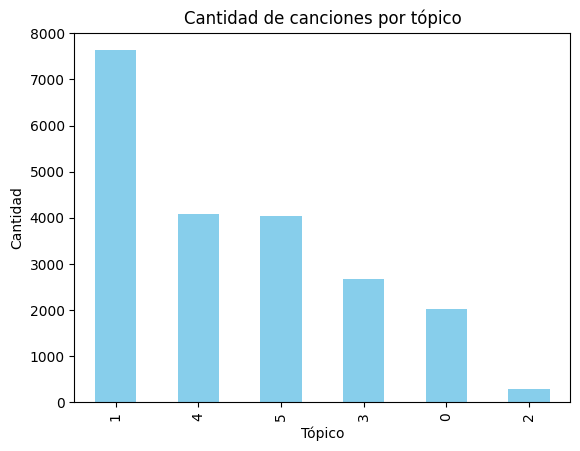

In [ ]:
corpus['topico_abs'].value_counts().plot(kind='bar', color='skyblue')
plt.title('Cantidad de canciones por tópico')
plt.xlabel('Tópico')
plt.ylabel('Cantidad')
plt.show()

Finalmente, graficamos la distribución de tópico por estilo. Corroboramos algunas hipótesis como:

- El tema principal de balada es desamor
- Más del 50% de las canciones de estilo religioso tienen como tópico con mayor probabilidad el 0
- Tradicional tiene gran mayoría de tema 3 (folklorico) pero también 5 (naturaleza) y 4 (desamor).
- Tropical tiene altas proporciones de temas 4 y 1, que son los temas relacionados a los sentimientos.

- Pop y rock tienen temas variados pero concentran sobre el tema 1 que es el más amplio

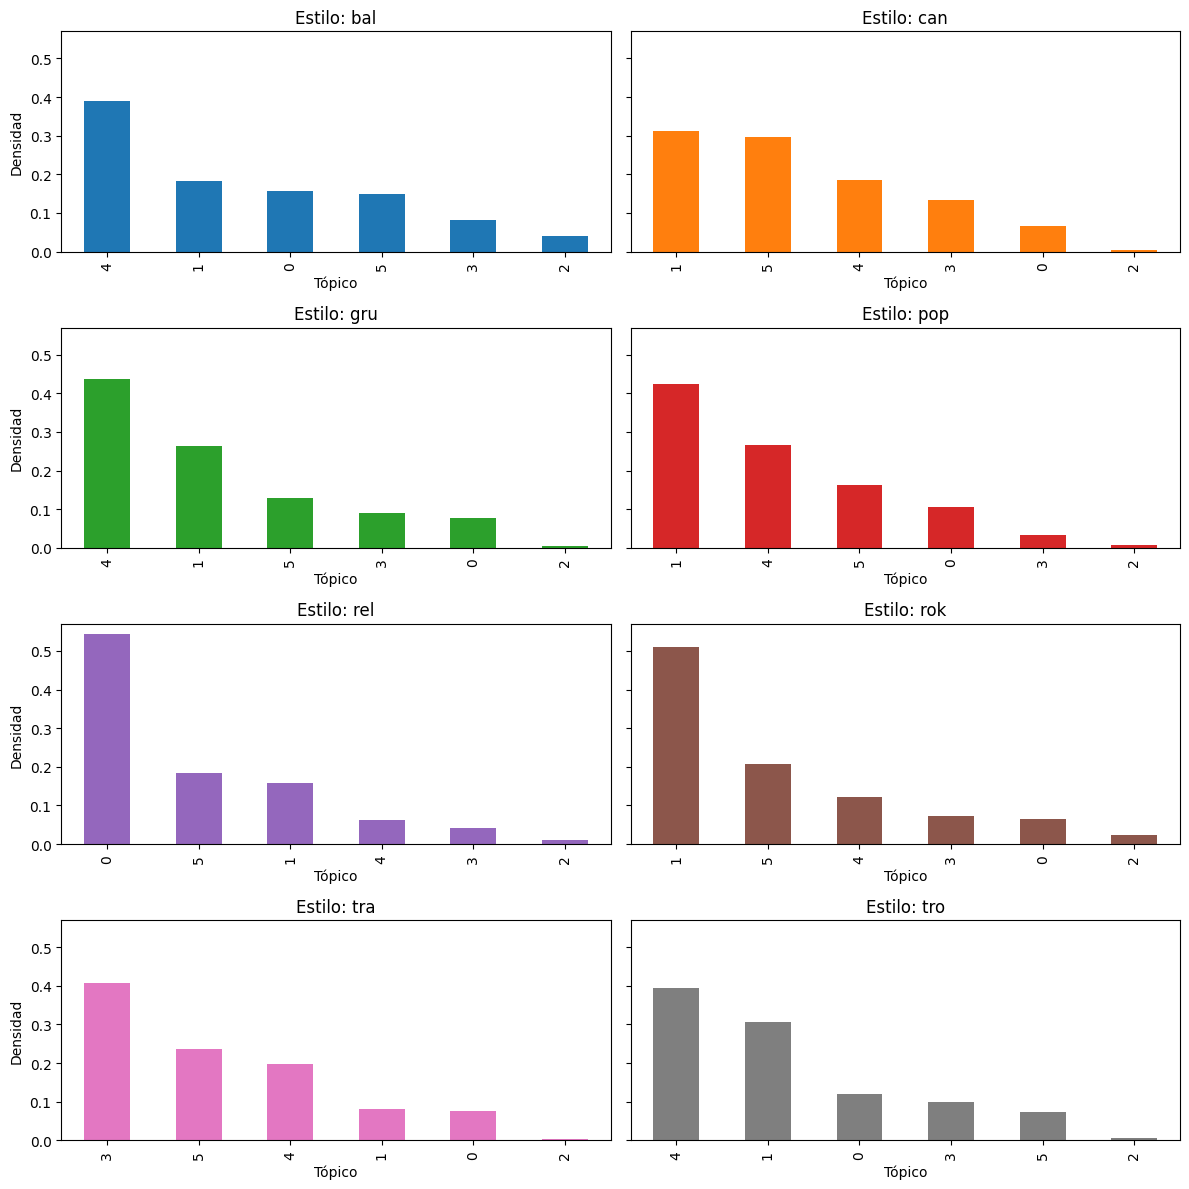

In [ ]:
import matplotlib.pyplot as plt

estilos = corpus['estilo'].unique()
n_estilos = len(estilos)
cols = 2
rows = (n_estilos + 1) // 2

fig, axes = plt.subplots(rows, cols, figsize=(12, 3 * rows), sharey=True)
axes = axes.flatten()

colors = plt.cm.tab10.colors

for i, estilo in enumerate(estilos):
    ax = axes[i]
    subset = corpus[corpus['estilo'] == estilo]
    # Normalized histogram (density)
    (subset['topico_abs'].value_counts(normalize=True)
         .plot(kind='bar', ax=ax, color=colors[i % len(colors)]))
    ax.set_title(f"Estilo: {estilo}")
    ax.set_xlabel('Tópico')
    ax.set_ylabel('Densidad')

for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

## Conclusiones

- A simple vista, los ejercicios 1, 2 y 3 no mostraban una separabilidad o agrupamiento marcado en los datos. Sin embargo, al aplicar Latent Dirichlet Allocation sí fue posible extraer conclusiones del conjunto de datos.

- La agrupación de tópicos de LDA no agrupa necesariamente en tópicos con la misma cantidad de datos. Esto es interesante porque permite encontrar tópicos marcados incluso si sus muestras no son representativas del total.

- Otro aspecto llamativo del análisis del punto 4 es el hecho de que letras de estilos muy diferentes musicalmente, es decir, en su sonoridad, pueden tener letras de tópicos similares. Existe un prejuicio de que distintos géneros suelen tener letras muy diferentes y observamos que esto no pasaba en muchos casos. Por ejemplo, canciones pop con temáticas existencialistas que quedaron en el tópico 1 junto a temas de estilo punk o las baladas que comparten categoría con temas tropicales por hablar de romance.

- Modificar híper-parámetros tiene efectos muy fuertes en los resultados que puedan obtenerse. La inclusión o no de stop-words, los filtrados de dataframes y los parámetros del modelo LDA hicieron que los resultados variaran mucho. En algunos casos dando conjuntos de tópicos más específicos donde algunas temáticas quedaban muy bien representadas pero muchos datos quedaban sin categoría clara. Finalmente, decidimos sobre este conjunto que nos pareció un buen *trade-off* pero posiblemente existan combinaciones que puedan dar otras perspectivas.